# 1. Data exploration: MMRDR colour fundus photographs

Reads the outputs of `python -m drxai.prepare`: the manifest, the integrity report and the duplicate audit.
Nothing here alters the data or the splits. Run `prepare` first.

In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from drxai import GRADE_NAMES
from drxai.config import REPO_ROOT, cache_dir, load_config, resolve

# Read-only: this notebook loads files written by the pipeline commands and computes nothing that is reported elsewhere.
cfg = load_config(os.environ.get("DRXAI_CONFIG", REPO_ROOT / "configs" / "default.yaml"))
CACHE = cache_dir(cfg)
RUNS = resolve(cfg["paths"]["runs_dir"])

In [2]:
man = pd.read_csv(CACHE / "manifest.csv", dtype={"image_id": str, "group": str})
report = json.loads((CACHE / "integrity_report.json").read_text())
print(f"{len(man)} images | split source: {report['split_source']}")
print("column mapping:", report["column_mapping"])

11062 images | split source: official
column mapping: {'image_id': 'image', 'grade': 'grade', 'eye': 'lr', 'patient_id': None, 'split': None}


## Integrity checks
Every check `prepare` ran. A failed critical check stops the pipeline, so all of these passed or are warnings.

In [3]:
checks = pd.DataFrame(report["checks"]).T
checks["status"] = np.where(checks["passed"], "PASS", np.where(checks["critical"], "FAIL", "WARN"))
checks[["status", "detail"]]

,status,detail
grades parse as numbers,PASS,0 unparseable rows dropped
grades within 0..K-1,PASS,"observed [0, 1, 2, 3, 4]"
image ids unique,PASS,0 duplicate ids
every id resolves to exactly one file with a matching stem,PASS,11118 files
near-duplicate pairs found,PASS,"169 pairs, 4 with different grades"
duplicate detector flags a plausible share of images,PASS,305 of 11118 images in a duplicate pair
split source,PASS,official
train near-copies of test images removed,PASS,56 training images dropped
no group spans train/val,PASS,0 shared groups
no group spans train/test,PASS,0 shared groups


## Grade distribution and class imbalance
The imbalance is why the sampler weights by the inverse square root of class frequency and why per-class recall is reported.

split,train,val,test
0 No DR,4462,744,1323
1 Mild NPDR,891,149,259
2 Moderate NPDR,1327,221,409
3 Severe NPDR,431,72,100
4 PDR,463,77,134


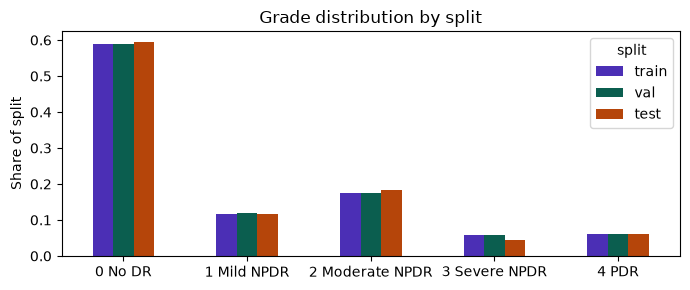

In [4]:
table = pd.crosstab(man["grade"], man["split"]).reindex(columns=["train", "val", "test"], fill_value=0)
table.index = [f"{g} {GRADE_NAMES[g]}" for g in table.index]
display(table)
ax = (table / table.sum()).plot.bar(figsize=(7, 3), rot=0, color=["#4B2FB5", "#0B5E4F", "#B5450A"])
ax.set_ylabel("Share of split"); ax.set_title("Grade distribution by split"); plt.tight_layout(); plt.show()

## Preprocessing: from raw photograph to cached image

`prepare` puts every image through the same four steps, using the functions in `src/drxai/data.py`. The cell below calls those functions directly on three training images, one of each surround type found in MMRDR.

1. **Raw photograph.** MMRDR images come from several cameras, at widths from about 1,150 to 3,300 pixels, with a circular field of view on a dark surround.
2. **Field-of-view mask.** A pixel counts as retina when its brightest colour channel is above a threshold, normally 10. The surround level is estimated from the four corners (the median of the four corner medians). One camera leaves a grey surround of about 20, which a threshold of 10 would count as retina. For those images the threshold becomes the surround level plus 10, and the surround is set to black. *Why:* the grey surround is almost absent at grade 0 (table at the end of the cell), so if it were left in place a model could read the grade from the border instead of the retina.
3. **Crop and square.** The image is cropped to the bounding box of the field of view, then padded with black to a square with the disc centred. *Why:* this removes empty border that differs between cameras, and squaring before resizing keeps the disc round rather than stretched.
4. **Cached image.** The square is resized to 448 by 448 pixels (bicubic) and saved as PNG. *Why:* decoding and cropping 11,000 large JPEGs every epoch would be slow. The 384-pixel network input is taken from this cache during training. The last column is read back from `cache/images/`, and the table confirms it is identical, pixel for pixel, to what the functions produce here.

**A white canvas is left as it is.** Five images show the fundus inside a black ring on a white canvas. Raising the threshold above white would remove the whole retina, so these keep the fixed threshold, and their white corners remain in the cached image (hard to see on this page's white background). All five are grade 4 and in the training split, so within training a white corner always goes with grade 4. No validation or test image has a white canvas, so this cannot affect any reported number, but it is a small shortcut available to the model during training and is listed as a limitation.

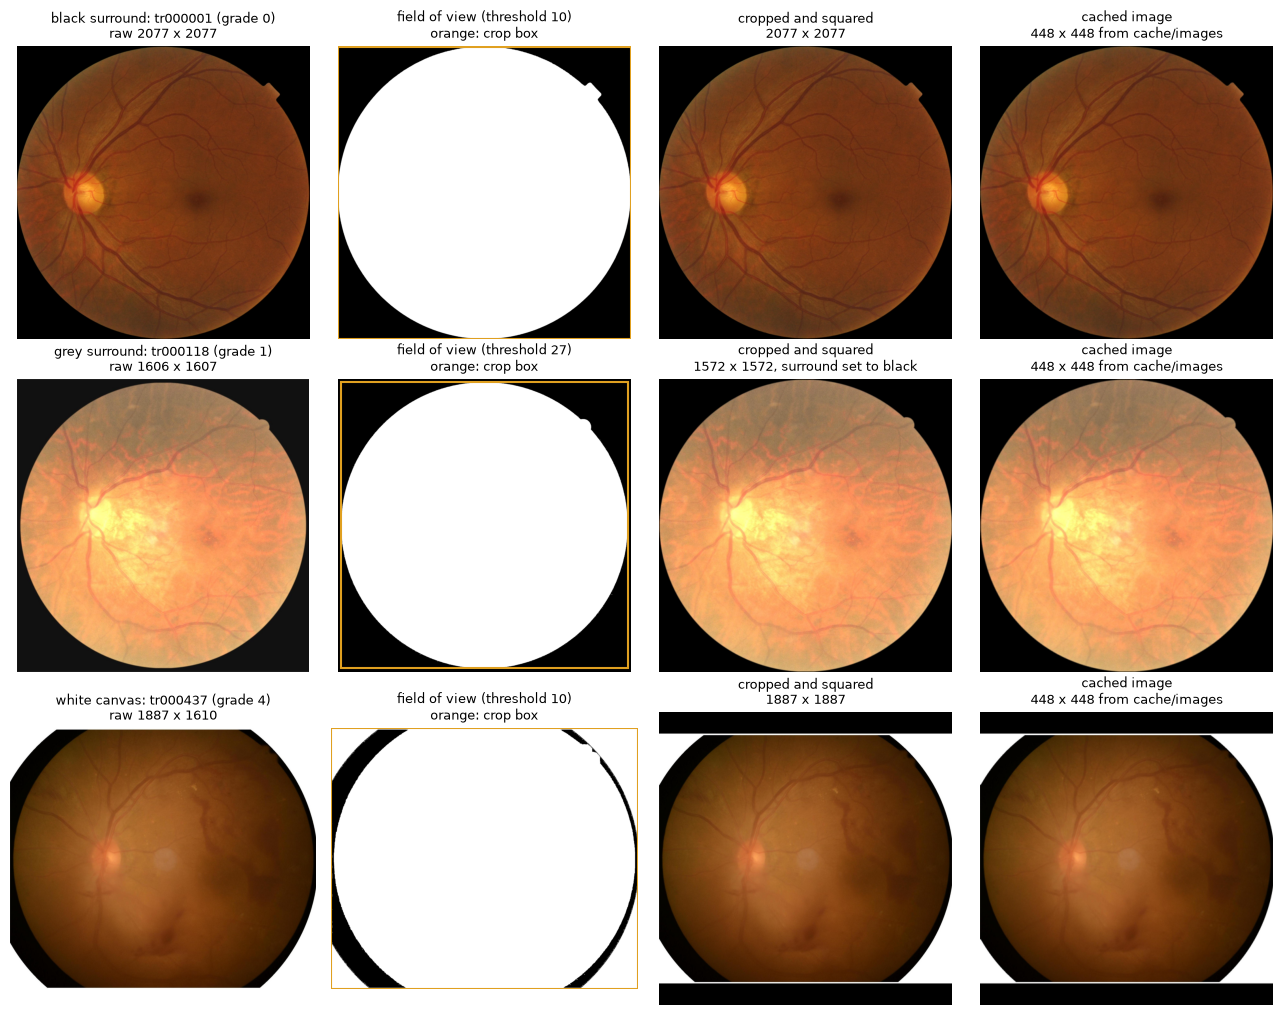

,type,grade,surround level,threshold,surround corrected,grey_surround in manifest,"crop box (x0, y0, x1, y1)",identical to cached file
image,,,,,,,,
tr000001,black surround,0,0.0,10,False,False,"(0, 3, 2077, 2077)",True
tr000118,grey surround,1,17.0,27,True,True,"(17, 17, 1589, 1587)",True
tr000437,white canvas,4,255.0,10,False,False,"(0, 0, 1887, 1610)",True


Grey-surround images by grade, training and validation only (317 corrected across all splits):


,black_surround,grey_surround,grey_share_pct
grade,,,
0,5181,25,0.5
1,946,94,9.0
2,1481,67,4.3
3,466,37,7.4
4,509,31,5.7


In [5]:
from PIL import Image
from matplotlib.patches import Rectangle

from drxai.data import crop_to_square, fov_mask, index_images, resolve_ids, retina_region, surround_level, surround_threshold

# One training image of each surround type found in MMRDR
EXAMPLES = {"black surround": "tr000001", "grey surround": "tr000118", "white canvas": "tr000437"}
meta = man.set_index("image_id")
assert (meta.loc[list(EXAMPLES.values()), "split"] == "train").all(), "examples must come from the training split"

index = index_images(resolve(cfg["paths"]["data_root"]) / cfg["paths"]["image_dir"])
size = cfg["data"]["cache_size"]
rows = []
fig, axes = plt.subplots(len(EXAMPLES), 4, figsize=(13, 3.4 * len(EXAMPLES)))
for r, (kind, iid) in enumerate(EXAMPLES.items()):
    img = Image.open(resolve_ids([iid], index)[0]).convert("RGB")
    rgb = np.asarray(img)
    thresh, corrected = surround_threshold(rgb)
    # what crop_to_square keeps: the solid retina region when the surround is corrected, else the plain threshold mask
    mask = retina_region(rgb, thresh) if corrected else fov_mask(rgb, thresh)
    out, g = crop_to_square(img, size)
    side = max(g.crop_x1 - g.crop_x0, g.crop_y1 - g.crop_y0)
    squared, _ = crop_to_square(img, side)              # same steps, before the resize to the cache size
    cached = Image.open(CACHE / "images" / f"{iid}.png")

    axes[r, 0].imshow(img)
    axes[r, 0].set_title(f"{kind}: {iid} (grade {meta.loc[iid, 'grade']})\nraw {g.orig_w} x {g.orig_h}", fontsize=9)
    axes[r, 1].imshow(mask, cmap="gray")
    axes[r, 1].add_patch(Rectangle((g.crop_x0, g.crop_y0), g.crop_x1 - g.crop_x0, g.crop_y1 - g.crop_y0,
                                   fill=False, edgecolor="#E0A020", linewidth=1.5))
    axes[r, 1].set_title(f"field of view (threshold {thresh})\norange: crop box", fontsize=9)
    axes[r, 2].imshow(squared)
    axes[r, 2].set_title(f"cropped and squared\n{side} x {side}" + (", surround set to black" if corrected else ""),
                         fontsize=9)
    axes[r, 3].imshow(cached)
    axes[r, 3].set_title(f"cached image\n{cached.size[0]} x {cached.size[1]} from cache/images", fontsize=9)
    for a in axes[r]:
        a.axis("off")
    rows.append({"image": iid, "type": kind, "grade": int(meta.loc[iid, "grade"]),
                 "surround level": surround_level(rgb), "threshold": thresh, "surround corrected": corrected,
                 "grey_surround in manifest": bool(meta.loc[iid, "grey_surround"]),
                 "crop box (x0, y0, x1, y1)": (g.crop_x0, g.crop_y0, g.crop_x1, g.crop_y1),
                 "identical to cached file": bool(np.array_equal(np.asarray(out), np.asarray(cached)))})
plt.tight_layout(); plt.show()
display(pd.DataFrame(rows).set_index("image"))

grey = pd.DataFrame(report["grey_surround_by_grade_train_val"])
grey.index.name = "grade"
print(f"Grey-surround images by grade, training and validation only ({report['n_grey_surround_corrected']} "
      f"corrected across all splits):")
display(grey)

## Training augmentation and evaluation transform

Listed rather than drawn: drawing examples needs torchvision, which imports PyTorch, and this notebook is kept free of it so it can run while a model is training. From `src/drxai/datasets.py`, with a network input of 384 pixels (`data.img_size`):

**Training** (a new random draw each time an image is used):
- `RandomResizedCrop(384, scale=(0.85, 1.0), ratio=(0.95, 1.05))`: keeps 85% to 100% of the image area with a near-square aspect, so framing and scale vary slightly.
- `RandomHorizontalFlip()` and `RandomVerticalFlip()`, then `RandomRotation(180)`: a fundus photograph has no fixed orientation for grading, so these add variety without changing the grade. (They would not be safe for OCT B-scans, where a vertical flip inverts the retinal layers.)
- `ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1)`: mimics differences in exposure and camera colour.
- `ToTensor()` and `Normalize` with the ImageNet mean and standard deviation, which the ImageNet-pretrained ResNet-50 expects.

**Evaluation** (validation and test): `Resize(384)`, `ToTensor()` and the same `Normalize`. Nothing is random, so an image always gives the same prediction.

## Example images per grade (training split)
The first two training images of each grade by id, after cropping. Chosen by rule, not by eye.

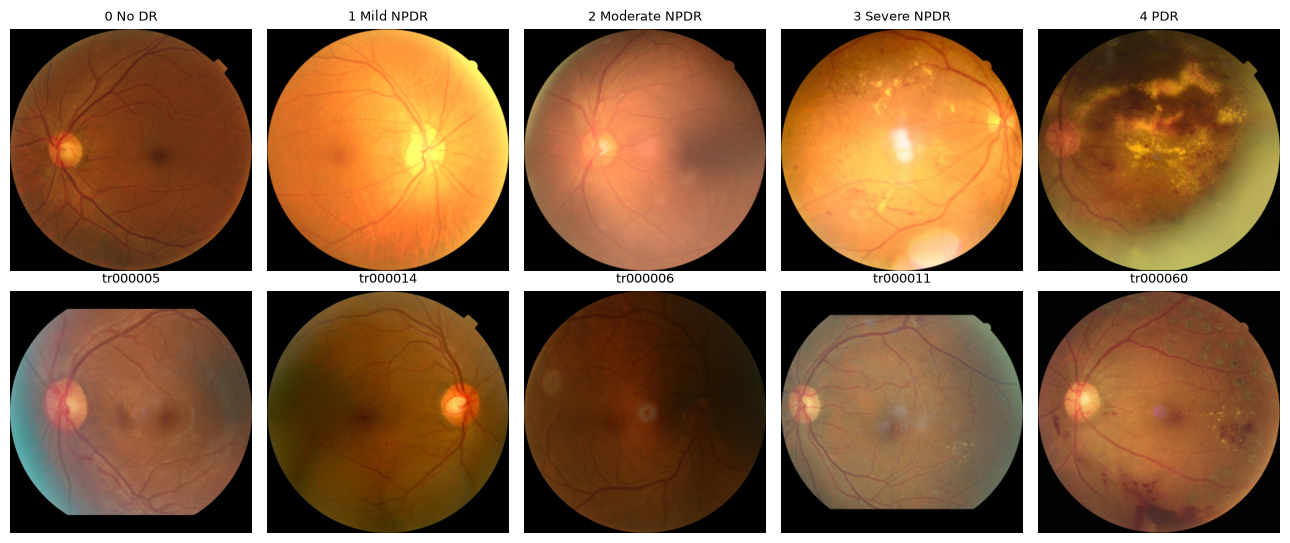

In [6]:
tr = man[man["split"] == "train"].sort_values("image_id")
fig, axes = plt.subplots(2, 5, figsize=(13, 5.5))
for g in range(5):
    rows = tr[tr["grade"] == g].head(2)
    for r in range(2):
        a = axes[r, g]; a.axis("off")
        if r < len(rows):
            a.imshow(plt.imread(CACHE / rows.iloc[r]["cache_path"]))
            a.set_title(f"{g} {GRADE_NAMES[g]}" if r == 0 else rows.iloc[r]["image_id"], fontsize=9)
plt.tight_layout(); plt.show()

## Image quality (all splits, descriptive)
Sharpness (variance of the Laplacian, green channel), brightness and contrast inside the field of view. The test-set analysis reports performance within sharpness bands whose edges come from these training images.

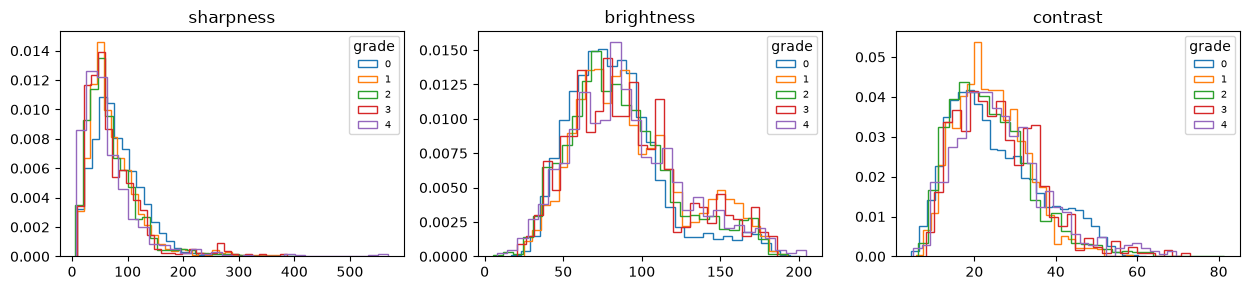

,q_sharpness,q_brightness,q_contrast
grade,,,
0,74.32,79.56,22.80
1,62.54,86.41,23.33
2,59.34,82.15,22.68
3,57.88,86.16,24.64
4,51.28,85.86,24.91


In [7]:
qcols = [c for c in ["q_sharpness", "q_brightness", "q_contrast"] if c in man.columns]
fig, axes = plt.subplots(1, len(qcols), figsize=(4.2 * len(qcols), 3))
for a, c in zip(np.atleast_1d(axes), qcols):
    for g in range(5):
        a.hist(man.loc[man.grade == g, c].dropna(), bins=30, histtype="step", label=str(g), density=True)
    a.set_title(c.replace("q_", "")); a.legend(title="grade", fontsize=7)
plt.tight_layout(); plt.show()
man.groupby("grade")[qcols].median().round(2)

223 least-sharp images (bottom 2%); grade mix: {0: 93, 1: 16, 2: 59, 3: 15, 4: 40}


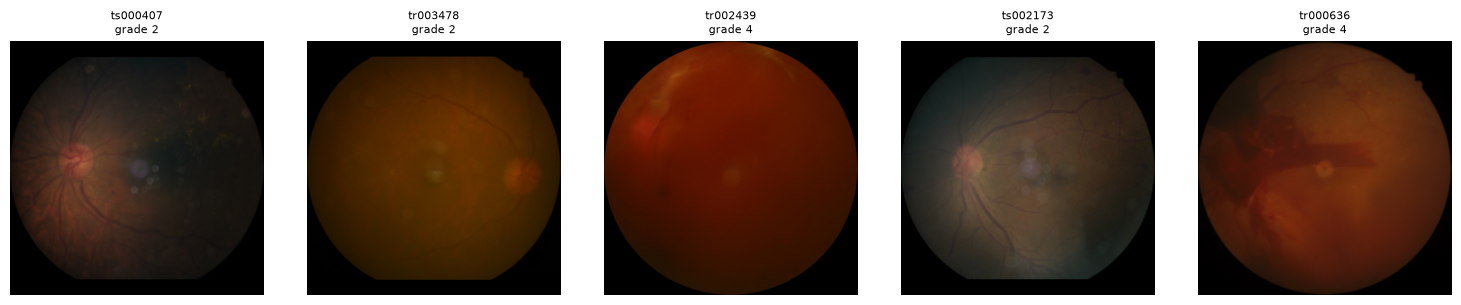

In [8]:
low = pd.read_csv(CACHE / "lowest_sharpness_2pct.csv", dtype={"image_id": str})
print(f"{len(low)} least-sharp images (bottom 2%); grade mix:", low["grade"].value_counts().sort_index().to_dict())
show = low.sort_values("q_sharpness").head(5)
fig, axes = plt.subplots(1, len(show), figsize=(3 * max(len(show), 1), 3), squeeze=False)
for a, (_, r) in zip(axes[0], show.iterrows()):
    a.imshow(plt.imread(CACHE / f"images/{r.image_id}.png")); a.axis("off"); a.set_title(f"{r.image_id}\ngrade {r.grade}", fontsize=8)
plt.tight_layout(); plt.show()

## Duplicate audit
The same photograph stored under two ids, found by correlating high-pass fingerprints. Training images that duplicate a test image are removed; the test set is never changed. Pairs whose grades disagree are label noise.

In [9]:
dup = pd.read_csv(CACHE / "near_duplicates.csv", dtype={"id_a": str, "id_b": str})
print(f"{len(dup)} duplicate pairs; {int((dup.grade_a != dup.grade_b).sum())} with different grades; "
      f"{report.get('n_train_dropped_as_test_duplicates', 0)} training images dropped")
dup.sort_values("corr", ascending=False).head(10)

169 duplicate pairs; 4 with different grades; 56 training images dropped


,id_a,id_b,corr,grade_a,grade_b
1,tr000270,tr001445,1.0,0,0
5,tr000506,ts000869,1.0,0,0
2,tr000439,tr005040,1.0,0,0
3,tr000465,tr002555,1.0,0,0
4,tr000494,tr000809,1.0,0,0
7,tr000559,tr007488,1.0,0,0
6,tr000519,tr004852,1.0,0,0
8,tr000586,ts000035,1.0,0,0
11,tr000754,tr001907,1.0,0,0
39,tr001801,tr003235,1.0,0,0


## Limitation
No patient identifiers are available, so different photographs of the same eye cannot be kept on one side of a split. The duplicate audit catches copies of a photograph, not repeat photographs.